# Лабораторна робота №6. Робота з відкритим програмним кодом

**Горбач Ангеліна, ФІ-31**

**Тема.** Детекція об’єктів на зображенні за допомогою YOLOv10n.

**Мета.** Розібратися, як працює відкритий код YOLOv10, запустити демонстрацію з вагами авторів і проаналізувати результат.

[Стаття Wang та ін. (2024)](https://arxiv.org/abs/2405.14458) · [Репозиторій авторів THU-MIG/yolov10](https://github.com/THU-MIG/yolov10)

## 1. Ідея статті

У статті автори розглядають таку ситуацію: на фото є один автобус, а детектор може намалювати навколо нього кілька схожих рамок. Зазвичай після прогнозу застосовують NMS. Якщо рамки сильно перекриваються, цей метод залишає рамку з вищою оцінкою, а решту відкидає. Це додає ще один крок до обробки зображення.

У YOLOv10 автори змінили саме навчання моделі. Вони використали дві гілки. У гілці one-to-many модель вчиться на кількох відповідних прогнозах для кожного об’єкта. У гілці one-to-one до кожного об’єкта підбирають один прогноз. Коли модель обробляє нове фото, вона бере результат другої гілки. Так автори змогли прибрати окремий крок з NMS. Вони також змінили деякі частини моделі, щоб вона потребувала менше обчислень.

На наборі COCO версія YOLOv10-S у тестах авторів працювала в 1,8 раза швидше за RT-DETR-R18, а оцінка якості детекції (AP) була близькою. Для своєї роботи я взяла меншу версію YOLOv10n і запустила її на одному фото, щоб подивитися, які об’єкти вона знайде і де проведе рамки.

## 2. Підготовка середовища і завантаження коду

In [1]:
import hashlib
import os
from pathlib import Path
import shutil
import subprocess
import sys
from unittest.mock import patch
from urllib.request import urlretrieve

repo_url = "https://github.com/THU-MIG/yolov10.git"
revision = "453c6e38a51e9d1d5a2aa5fb7f1014a711913397"
work_dir = Path.cwd() / "lr6_yolov10"
repo_dir = work_dir / "source"

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "huggingface-hub==0.23.2", "thop==0.1.1.post2209072238", "py-cpuinfo",
])

work_dir.mkdir(exist_ok=True)
if not (repo_dir / ".git").is_dir():
    subprocess.check_call(["git", "init", "-q", str(repo_dir)])

current_revision = subprocess.run(
    ["git", "-C", str(repo_dir), "rev-parse", "--verify", "HEAD"],
    capture_output=True, text=True,
)
if current_revision.stdout.strip() != revision:
    subprocess.check_call([
        "git", "-C", str(repo_dir), "fetch", "-q", "--depth", "1", repo_url, revision,
    ])
    subprocess.check_call(["git", "-C", str(repo_dir), "checkout", "-q", "--detach", "FETCH_HEAD"])

if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))

print(f"Версія коду авторів: {revision[:12]}")

Версія коду авторів: 453c6e38a51e


## 3. Запуск демо на зображенні з GitHub

Для демо я взяла фото `bus.jpg` із репозиторію авторів і запустила модель із готовими вагами `yolov10n.pt`. Встановила поріг `conf=0.25`, тому на фото залишилися лише рамки, яким модель дала оцінку понад 0,25.

Число біля кожної рамки показує, наскільки модель упевнена, що правильно визначила об’єкт саме в цій рамці. Щоб оцінити якість моделі загалом, її прогнози порівнюють із розміткою на наборі зображень.

In [2]:
import torch
from IPython.display import display
from PIL import Image
from ultralytics import YOLOv10

weights_url = "https://github.com/THU-MIG/yolov10/releases/download/v1.1/yolov10n.pt"
weights_sha256 = "61b91ffc99b284792dca49bf40216945833cc2a515e1a742954e6e9327cfc19e"
weights_path = work_dir / "yolov10n.pt"

if not weights_path.is_file() or hashlib.sha256(weights_path.read_bytes()).hexdigest() != weights_sha256:
    downloaded_weights = work_dir / "yolov10n.pt.download"
    urlretrieve(weights_url, downloaded_weights)
    if hashlib.sha256(downloaded_weights.read_bytes()).hexdigest() != weights_sha256:
        raise ValueError("Контрольна сума завантажених ваг не збігається.")
    downloaded_weights.replace(weights_path)

with patch.dict(os.environ, {"TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD": "1"}):
    model = YOLOv10(str(weights_path))

device = 0 if torch.cuda.is_available() else "cpu"
image_path = repo_dir / "ultralytics" / "assets" / "bus.jpg"
result = model.predict(source=str(image_path), imgsz=640, conf=0.25, device=device)[0]
print(f"Пристрій: {'GPU' if device == 0 else 'CPU'}")

/content/lr6_yolov10/source/ultralytics/nn/tasks.py:733: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  ckpt = torch.load(file, map_location="cpu")



image 1/1 /content/lr6_yolov10/source/ultralytics/assets/bus.jpg: 640x480 4 persons, 1 bus, 373.1ms
Speed: 18.7ms preprocess, 373.1ms inference, 24.1ms postprocess per image at shape (1, 3, 640, 480)
Пристрій: CPU


## 4. Зображення з рамками і таблиця детекцій

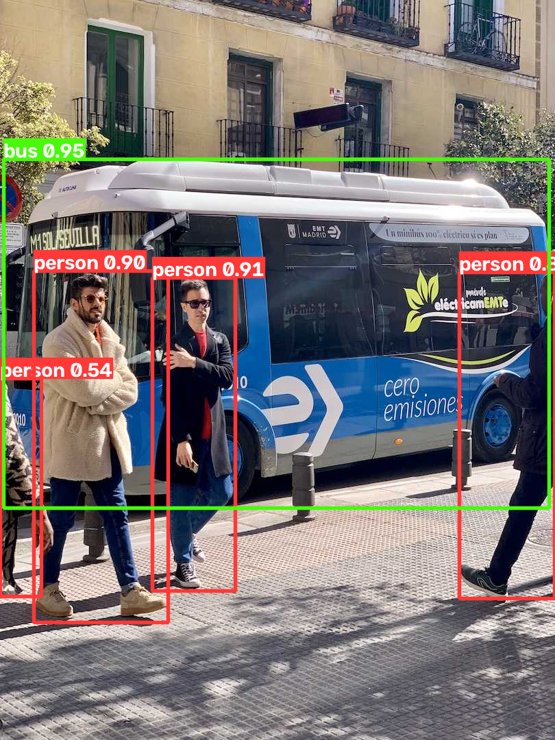

Усього детекцій: 5


,class,confidence,x1,y1,x2,y2
0,bus,0.948,5.8,232.6,802.0,741.6
1,person,0.907,222.6,405.2,343.7,862.4
2,person,0.898,49.3,395.4,245.9,908.8
3,person,0.891,670.0,397.3,809.7,873.3
4,person,0.543,0.3,552.9,60.4,870.8


,Кількість
class,
person,4
bus,1


Архів із результатами: /content/lr6_yolov10/LR6_results.zip


In [3]:
import pandas as pd

output_dir = work_dir / "results"
output_dir.mkdir(exist_ok=True)
annotated_path = output_dir / "bus_detections.jpg"
csv_path = output_dir / "bus_detections.csv"

# Plot returns a BGR array, while Pillow expects RGB.
annotated = Image.fromarray(result.plot()[:, :, ::-1])
annotated.save(annotated_path, quality=95)
preview = annotated.copy()
preview.thumbnail((740, 740))
display(preview)

rows = []
for box in result.boxes:
    label = result.names[int(box.cls.item())]
    x1, y1, x2, y2 = box.xyxy[0].cpu().tolist()
    rows.append([label, round(box.conf.item(), 3), *[round(x, 1) for x in (x1, y1, x2, y2)]])

detections = pd.DataFrame(rows, columns=["class", "confidence", "x1", "y1", "x2", "y2"])
detections = detections.sort_values("confidence", ascending=False).reset_index(drop=True)
detections.to_csv(csv_path, index=False)
print(f"Усього детекцій: {len(detections)}")
display(detections)
if not detections.empty:
    display(detections["class"].value_counts().rename("Кількість").to_frame())

archive_path = shutil.make_archive(str(work_dir / "LR6_results"), "zip", output_dir)
print(f"Архів із результатами: {archive_path}")

Кожна рамка в таблиці задана двома кутами. `x1, y1` — координати верхнього лівого кута, а `x2, y2` — нижнього правого. Усі координати наведені в пікселях початкового фото. Фото з рамками й таблицю у форматі CSV я зберегла в архіві `LR6_results.zip`.

## 5. Де в коді авторів відбувається детекція

| Файл | Що в ньому відбувається |
| --- | --- |
| [`engine/predictor.py`](https://github.com/THU-MIG/yolov10/blob/453c6e38a51e9d1d5a2aa5fb7f1014a711913397/ultralytics/engine/predictor.py) | `BasePredictor.preprocess` готує зображення до входу моделі: змінює розмір із доповненням, переводить кольори у RGB, перетворює масив на тензор і масштабує значення пікселів до 0–1. |
| [`nn/modules/head.py`](https://github.com/THU-MIG/yolov10/blob/453c6e38a51e9d1d5a2aa5fb7f1014a711913397/ultralytics/nn/modules/head.py) | `v10Detect.forward` формує вихід голови детекції для гілки `one2one`, яку використовує демо. |
| [`utils/loss.py`](https://github.com/THU-MIG/yolov10/blob/453c6e38a51e9d1d5a2aa5fb7f1014a711913397/ultralytics/utils/loss.py) | `v10DetectLoss` поєднує втрати для двох гілок під час навчання. У демо завантажуються готові ваги. |
| [`models/yolov10/predict.py`](https://github.com/THU-MIG/yolov10/blob/453c6e38a51e9d1d5a2aa5fb7f1014a711913397/ultralytics/models/yolov10/predict.py) | `YOLOv10DetectionPredictor.postprocess` бере вихід `one2one`, відбирає детекції за оцінкою та повертає рамки в координатах вихідного зображення. |

In [4]:
import inspect
from ultralytics.models.yolov10.predict import YOLOv10DetectionPredictor
from ultralytics.nn.modules.head import v10Detect

for function in (v10Detect.forward, YOLOv10DetectionPredictor.postprocess):
    file_path = Path(inspect.getsourcefile(function))
    first_line = inspect.getsourcelines(function)[1]
    print(f"{function.__qualname__}: {file_path.relative_to(repo_dir)}:{first_line}")

v10Detect.forward: ultralytics/nn/modules/head.py:511
YOLOv10DetectionPredictor.postprocess: ultralytics/models/yolov10/predict.py:8


## 6. Можливе покращення детекції дрібних об’єктів

Коли велике фото зменшують перед запуском моделі, дрібні об’єкти стають ще менш помітними. Я б спробувала поділити фото на фрагменти й обробити кожен окремо. Сусідні фрагменти мають трохи перекриватися, щоб об’єкти на межі не обрізалися. Потім рамки можна перенести на ціле фото й прибрати повтори, якщо модель знайшла той самий об’єкт у двох фрагментах.

Щоб перевірити, чи це допомагає, я б використала ті самі розмічені фото для двох запусків: на цілих зображеннях і на фрагментах. Порівняла б AP для малих об’єктів і час обробки одного фото. На фрагментах модель може знайти більше дрібних об’єктів, але обробка, ймовірно, займе більше часу.

## Висновок

Я запустила YOLOv10n у Google Colab на CPU з кодом і готовими вагами авторів. На фото `bus.jpg` модель знайшла чотирьох людей і один автобус. Для автобуса оцінка впевненості становила 0,948, а для людей — від 0,543 до 0,907. Сам прогноз зайняв приблизно 0,37 с.

Я також розібралася, як модель формує рамки на фото. Під час прогнозу вона використовує результат гілки `one2one` і залишає рамки з оцінкою впевненості понад 0,25. Потім координати цих рамок перераховуються, щоб їх можна було нанести на початкове зображення.